# 09. PeakFocus — 용담댐 시간 유입량 예측 (입력세트 A / B / C)

**모델**: PeakFocus (`model: peakfocus`) — 주의(첨두 과제 결합)
**한 줄 요약**: 첨두 위치 분류(MSM-PL)와 유량 회귀를 함께 학습하고, 위치 인식 디코더(LAD)가 첨두 특징으로 교차주의를 게이팅.

이 노트북은 모델 비교 연구(10개 모델 × 3개 입력세트)의 **PeakFocus 부분**입니다. 모든 모델 노트북이 같은 구성을 가집니다.

1. 모델 설명 (논문 methodology용)
2. 자료와 실험 설정
3. 학습 (입력세트 A, B, C) 과 학습곡선
4. 학습 / 검증 / 테스트 기간 성능
5. 수문곡선 · 산점도 · 유량지속곡선
6. 홍수 첨두 재현
7. 결과 해석
8. 요약 (비교 노트북 `11_Comparison_Overall.ipynb`, `12_Comparison_Peaks.ipynb` 에서 사용하는 `results/peakfocus_<set>/` 생성)

**연구 설정 요약**

| 항목 | 내용 |
|---|---|
| 대상 | 용담댐 (유역면적 930.42 km²) 시간 유입량 (m³/s) |
| 기간 | 2006-01-01 ~ 2025-12-31 (20년, 175,320 시간) |
| 학습 / 검증 / 테스트 | 2006–2017 (12년) / 2018–2021 (4년) / 2022–2025 (4년) |
| 입력세트 A | 유역평균 강수량 `rf_avg` (1변수) |
| 입력세트 B | 관측소별 강수량 `rf_<관측소>` × 7 (7변수) |
| 입력세트 C | A + B (8변수) |
| 해상도 | 시간(hourly). MTS-LSTM만 일(daily) 강우를 추가로 사용 |
| 공통 학습 설정 | Adam, lr 1e-3, batch 256, MSE, seq_length 720 h, epoch 30–50 (early stopping patience 5), seed 111 |
| 평가 epoch | 검증 loss가 최소인 epoch (early stopping은 학습을 멈출 뿐 가중치를 되돌리지 않음) |
| 데이터셋 클래스 | `hourlycsv` (`data/YDDam_paper/`) — `prepare_data.py` 로 생성 |
| 설정 파일 | `configs/<model>_<set>.yml` — `make_configs.py` 로 생성 |
| 공통 코드 | `common.py` (run 관리·평가·그림), `model_docs.py` (모델 설명) |



## 1. 모델 설명 (Methodology)

**PeakFocus (joint peak localization + intensity regression; NeuralHydrology `peakfocus`)**

"첨두를 어디서, 얼마나 크게"를 **두 개의 과제로 분리해 동시에 학습**하는 모델이다.

- **인코더**: 잔차 MLP 블록(`mlp_layers`=2)으로 각 시각의 특징을 만든다.
- **MSM-PL (Multi-Scale Mixing Peak Locator)**: 특징을 2단계 피라미드(`n_scales`=2)로 다운/업샘플해 섞은 뒤 시각별 **첨두 로짓**을 낸다.
  목표 창(마지막 24시간)에서 "±3시간 안의 최대이면서 표준화 값 > 1"인 시각을 첨두로 라벨링하고, 가우시안으로 ±1시간을 부드럽게 한 soft label에
  **focal loss**($\alpha$=0.25, $\gamma$=2)를 적용한다 → `peak_focal` 정규화 항.
- **LAD (Location-Aware Decoder)**: 디코더의 교차주의가 첨두 특징으로 **게이팅**되어, 첨두로 판정된 시각의 정보가 유량 회귀에 더 크게
  반영된다.
- **손실**: $\mathcal{L} = \mathrm{MSE}_{\text{전체}} + 1.0\cdot\mathrm{Focal}_{\text{첨두}} + 1.0\cdot\mathrm{MSE}_{\text{첨두 시각만}}$
  (`peak_weighted_mse`는 첨두 라벨 시각에서만 평균한 MSE로, 첨두 크기가 다수의 비첨두 시각에 희석되지 않게 한다).

`predict_last_n: 24` 로 마지막 24시간을 모두 예측해 첨두 head를 학습하지만, 평가는 다른 모델과 같이 **각 창의 마지막 시각 예측**만 사용한다.
원 구현은 입력창을 창별 평균·표준편차로 정규화한 뒤 목표 변수의 과거 통계로 출력을 역정규화하는데, 본 설정에서는 목표(유입량)가 입력이 아니어서
역정규화가 불가능하므로 창별 정규화를 끄고(`peakfocus_instance_norm: false`) NeuralHydrology 의 전역 표준화 입력을 그대로 사용한다.

### 1.1 수문학적 관점에서의 특징

- 일반 MSE 학습은 전체 시간의 85%를 차지하는 저유량에 지배되어 첨두가 과소되기 쉽다. PeakFocus는 **첨두 시각을 별도 과제로 학습**해 이
  불균형을 직접 다룬다.
- 분류 head는 "첨두가 임박했는가"를 출력하므로, 댐 운영 관점의 **홍수 경보**로도 쓸 수 있는 부산물이다.
- 라벨 임계(표준화 1.0 ≈ 평균 + 1σ ≈ 114 m³/s)와 창(±3 h)은 시간 자료에 맞춰 정한 값이며, 라벨 정의가 성능에 민감하다.

### 1.2 본 연구에서의 설정

| 항목 | 값 | 이유 |
|---|---|---|
| `peakfocus_d_model` / `n_heads` / `d_ff` | 64 / 4 / 128 | Transformer와 동일 |
| `peakfocus_d_layers` / `mlp_layers` / `n_scales` | 1 / 2 / 2 | 논문 설정 |
| `peakfocus_if_msm_pl` / `if_lad` | true / true | 두 구성요소 모두 사용 |
| `peakfocus_instance_norm` | false | 원 논문의 입력창 정규화는 목표 이력으로 역정규화하는 전제. 여기서는 목표가 입력이 아니므로 정규화를 끄고 전역 표준화 입력을 그대로 사용 (켜면 강우 절대 크기 정보가 사라져 학습 불가) |
| `predict_last_n` | 24 | 첨두 head 학습용 목표 창 |
| `regularization` | peak_focal 1.0, peak_weighted_mse 1.0 | 3중 손실 |
| `peak_label_window` / `threshold` | 3 / 1.0 | ±3 h 최대, 표준화 > 1 |
| `peak_soft_label_sigma` / `tolerance` | 2.0 / 1 | soft label |
| `peak_focal_alpha` / `gamma` | 0.25 / 2.0 | focal loss |

### 참고문헌

- Lin, T.-Y., Goyal, P., Girshick, R., He, K., & Dollár, P. (2017). Focal loss for dense object detection. *ICCV*.
- PeakFocus 참조 구현(`proposed_model.py`: Multi_Scale_Mixing_Peak_Locator, Location_Aware_Decoder_Layer)의 NeuralHydrology 이식.


## 2. 자료와 실험 설정

`common.py` 가 run 디렉터리 탐색, 평가, 그림을 모두 담당하므로 노트북 코드는 짧습니다. 아래 셀은 공통 설정을 불러오고 그림 스타일(큰 글꼴,
300 dpi 저장)을 지정합니다.

In [1]:
%matplotlib inline
import sys, warnings
warnings.filterwarnings("ignore", message=".*IProgress.*")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd()))
import common
from common import SETS, MODEL_NAME, MODEL_COLOR, SET_COLOR, SET_STYLE, PERIODS, PERIOD_LABEL
from model_docs import MODEL_DOCS, MODEL_FAMILY

warnings.filterwarnings("ignore", category=FutureWarning)
common.set_plot_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

MODEL = "peakfocus"
NAME = MODEL_NAME[MODEL]
print(NAME, "->", common.MODEL_SPECS[MODEL]["nh_model"])

PeakFocus -> peakfocus


### 2.1 자료 개요

연도별 유역평균 강수량과 유입량(평균·최대)입니다. 음영은 학습(회색) / 검증(주황) / 테스트(녹색) 기간입니다.
테스트 기간(2022–2025)에는 2023년과 2024년의 큰 홍수가 포함되어 있고, 학습 기간에는 2020년(최대 4,395 m³/s)이 **포함되지 않는다**는 점에 유의합니다
(2020년은 검증 기간). 즉 모델은 학습에서 본 적 없는 크기의 홍수를 검증·테스트에서 재현해야 하며, 이것이 모델 간 외삽 능력 차이를 드러냅니다.

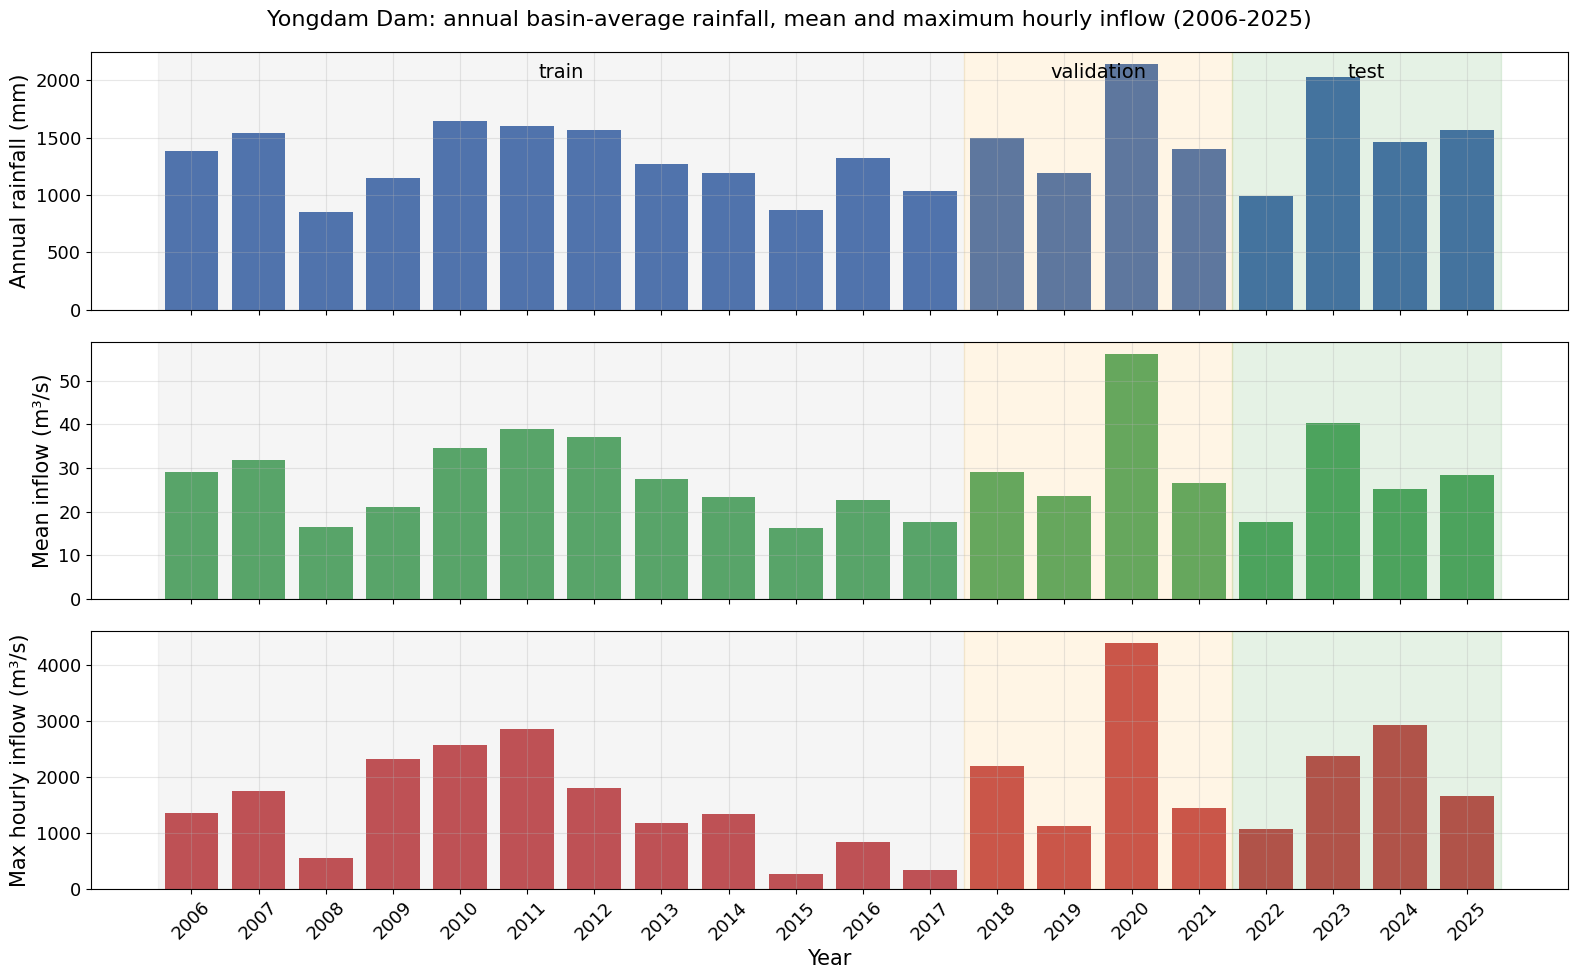

In [2]:
rain = common.load_rainfall(["rf_avg"])["rf_avg"]
inflow = common.load_observed_inflow()
annual = pd.DataFrame({"rain_mm": rain.resample("YE").sum(), "inflow_mean": inflow.resample("YE").mean(),
                       "inflow_max": inflow.resample("YE").max()})
annual.index = annual.index.year
annual = annual.loc[2006:2025]

fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
axes[0].bar(annual.index, annual["rain_mm"], color="#4c72b0")
axes[0].set_ylabel("Annual rainfall (mm)")
axes[1].bar(annual.index, annual["inflow_mean"], color="#55a868")
axes[1].set_ylabel("Mean inflow (m³/s)")
axes[2].bar(annual.index, annual["inflow_max"], color="#c44e52")
axes[2].set_ylabel("Max hourly inflow (m³/s)")
for ax in axes:
    ax.axvspan(2005.5, 2017.5, color="gray", alpha=0.08)
    ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
    ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
axes[0].text(2011.5, axes[0].get_ylim()[1] * 0.9, "train", ha="center", fontsize=14)
axes[0].text(2019.5, axes[0].get_ylim()[1] * 0.9, "validation", ha="center", fontsize=14)
axes[0].text(2023.5, axes[0].get_ylim()[1] * 0.9, "test", ha="center", fontsize=14)
axes[2].set_xlabel("Year")
axes[2].set_xticks(annual.index)
axes[2].tick_params(axis="x", rotation=45)
fig.suptitle("Yongdam Dam: annual basin-average rainfall, mean and maximum hourly inflow (2006-2025)", fontsize=16)
fig.tight_layout()
plt.show()


### 2.2 입력세트별 설정 파일

세 입력세트의 설정은 `dynamic_inputs` (와 모델에 따라 그에 연동된 몇 개 키)만 다릅니다. 아래 표는 공통 설정과 다른 항목만 보여 줍니다.
전체 파일은 `configs/peakfocus_<set>.yml` 입니다.

In [3]:
rows = {}
for s in SETS:
    rows[f"Set {s}"] = {k: str(v) for k, v in common.model_specific_config(MODEL, s).items()}
cfg_table = pd.DataFrame(rows).fillna("")
display(cfg_table)
print(Path(common.config_path(MODEL, "A")).read_text())

,Set A,Set B,Set C
experiment_name,peakfocus_A,peakfocus_B,peakfocus_C
predict_last_n,24,24,24
model,peakfocus,peakfocus,peakfocus
peakfocus_d_model,64,64,64
peakfocus_n_heads,4,4,4
peakfocus_d_ff,128,128,128
peakfocus_d_layers,1,1,1
peakfocus_mlp_layers,2,2,2
peakfocus_dropout,0.1,0.1,0.1
peakfocus_n_scales,2,2,2


experiment_name: peakfocus_A
run_dir: null
train_basin_file: YDDam_basin.txt
validation_basin_file: YDDam_basin.txt
test_basin_file: YDDam_basin.txt
train_start_date: 01/01/2006
train_end_date: 31/12/2017
validation_start_date: 01/01/2018
validation_end_date: 31/12/2021
test_start_date: 01/01/2022
test_end_date: 31/12/2025
seed: 111
device: cuda:0
validate_every: 1
validate_n_random_basins: 1
metrics:
- NSE
- KGE
head: regression
output_activation: linear
optimizer: Adam
loss: MSE
learning_rate:
  0: 0.001
batch_size: 256
epochs: 50
clip_gradient_norm: 1
early_stopping: true
patience_early_stopping: 5
minimum_epochs_before_early_stopping: 30
patience_dynamic_learning_rate: 3
factor_dynamic_learning_rate: 0.5
seq_length: 720
predict_last_n: 24
num_workers: 4
log_interval: 100
log_tensorboard: false
log_n_figures: 0
save_weights_every: 1
save_validation_results: false
dataset: hourlycsv
data_dir: ../../data/YDDam_paper
forcings:
- hourly
target_variables:
- inflow
clip_targets_to_zero:
-

## 3. 학습

`common.train()` 은 완료된 run (`runs/peakfocus_<set>_<날짜>_<시각>/`) 이 있으면 학습을 건너뛰고, 없으면 `nh-run train` 을 서브프로세스로
실행합니다 (`train_all.py` 로 미리 학습해 두어도 같은 run 을 사용합니다). 이어서 `common.evaluate_run()` 이

1. `output.log` 에서 epoch별 학습/검증 loss 와 검증 NSE/KGE 를 읽고,
2. 검증 loss 최소 epoch 을 골라 학습·검증·테스트 기간을 평가(`nh-run evaluate`)하고,
3. 시간 단위 예측을 m³/s 로 통일해 지표를 계산한 뒤 `results/peakfocus_<set>/` 에 저장합니다.

In [4]:
summaries, histories, preds = {}, {}, {}
for s in SETS:
    run_dir = common.train(MODEL, s, in_process=False)
    summaries[s] = common.evaluate_run(MODEL, s, run_dir)
    histories[s] = common.load_saved_history(MODEL, s)
    preds[s] = common.load_saved_predictions(MODEL, s)
    print(f"Set {s}: run={summaries[s]['run_dir']}  epochs={summaries[s]['epochs_trained']}  best={summaries[s]['best_epoch']}  "
          f"params={summaries[s]['n_parameters']:,}  {summaries[s]['epoch_time_mean_s']:.0f} s/epoch")

[peakfocus_A] completed run found, skipping training: peakfocus_A_2110_081917
Set A: run=peakfocus_A_2110_081917  epochs=37  best=21  params=92,762  20 s/epoch
[peakfocus_B] completed run found, skipping training: peakfocus_B_2110_081917
Set B: run=peakfocus_B_2110_081917  epochs=37  best=17  params=95,066  22 s/epoch
[peakfocus_C] completed run found, skipping training: peakfocus_C_2110_081917


Set C: run=peakfocus_C_2110_081917  epochs=44  best=17  params=95,450  20 s/epoch


### 3.1 학습곡선

왼쪽: 학습 loss(표준화된 MSE), 가운데: 검증 loss, 오른쪽: 검증 기간(2018–2021) NSE. 점선은 검증 loss 최소 epoch(평가에 쓴 체크포인트)입니다.
early stopping 은 30 epoch 이후 검증 loss 가 5 epoch 연속 개선되지 않으면 학습을 멈춥니다.

- 학습 loss 가 계속 내려가는데 검증 loss 가 올라가면 **과적합**, 둘 다 높은 채 머물면 **표현력 부족 또는 학습률 문제**입니다.
- 검증 NSE 가 들쭉날쭉하면 2020년 대홍수(검증 기간) 재현이 epoch 마다 흔들린다는 뜻입니다.

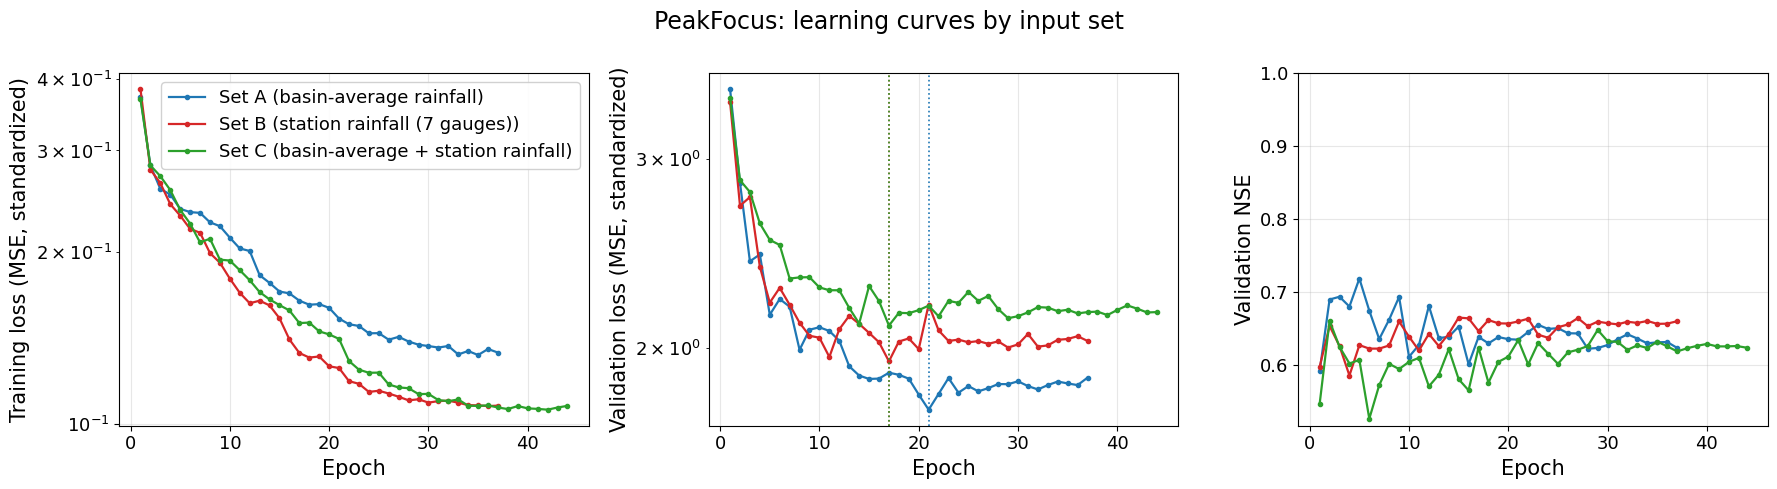

In [5]:
fig = common.plot_learning_curves(histories, title=f"{NAME}: learning curves by input set",
                                  labels={s: f"Set {s} ({common.INPUT_SET_NAMES[s]})" for s in SETS},
                                  colors=SET_COLOR, styles={s: "-" for s in SETS},
                                  best_epochs={s: summaries[s]["best_epoch"] for s in SETS})
common.save_fig(fig, f"{MODEL}_learning_curves")
plt.show()

## 4. 학습 / 검증 / 테스트 기간 성능

모든 지표는 **시간 단위, m³/s** 로 계산합니다 (MC-LSTM 의 mm/h 예측도 변환). 지표의 의미:

| 지표 | 의미 | 이상값 |
|---|---|---|
| NSE | 관측 평균 대비 설명력. 제곱오차 기반이라 **홍수(고유량)** 에 민감 | 1 |
| KGE | 상관(r)·변동성비(α)·편향비(β)를 함께 보는 지표 | 1 |
| RMSE / MAE | 오차의 크기 (m³/s) | 0 |
| PBIAS | 총량 편향(%) (+ 과대, − 과소) | 0 |
| Alpha-NSE / Beta-NSE | 표준편차 비 / 평균 편향(관측 표준편차로 정규화) | 1 / 0 |
| FHV / FMS / FLV | 유량지속곡선의 고유량(상위 2%) / 중간 구간 기울기 / 저유량(하위 30%) 편향(%) | 0 |
| Peak-Timing | 관측 첨두(자동 탐지)의 시각 오차 평균(h) | 0 |
| Peak-MAPE | 자동 탐지된 모든 첨두의 평균 절대 백분율 오차(%) | 0 |
| Missed-Peaks | 자동 탐지 첨두 중 예측이 놓친 비율 | 0 |

(첨두 자동 탐지는 라이브러리 기본 규칙으로 작은 첨두까지 포함하므로 값이 큽니다. 큰 홍수사건에 대한 분석은 6절과 `" + NB_PEAKS + "` 참고.)

In [6]:
rows = []
for s in SETS:
    for p in PERIODS:
        rows.append({"set": s, "period": p, **summaries[s]["metrics"][p]})
metrics_long = pd.DataFrame(rows).set_index(["set", "period"])[common.MAIN_METRICS]
display(metrics_long.round(3))
metrics_long.to_csv(common.RESULTS_DIR / f"{MODEL}_metrics_by_period.csv")

NSE    KGE    RMSE     MAE   PBIAS  Pearson-r  Alpha-NSE  Beta-NSE     FHV     FMS      FLV  Peak-Timing  Peak-MAPE  Missed-Peaks
set period                                                                                                                                         
A   train       0.688  0.497  40.156  17.121  44.453      0.901      1.213     0.164  19.033  21.647   96.907        4.351     47.155         0.654
    validation  0.635  0.628  70.768  22.680  32.834      0.825      1.018     0.095   7.737  31.595   97.982        3.659     49.078         0.665
    test        0.612  0.414  53.995  20.421  53.872      0.864      1.186     0.174  18.348 -28.106   97.329        3.135     36.718         0.658
B   train       0.792  0.699  33.017  14.291  24.740      0.924      1.154     0.091  13.493  28.559 -122.714        4.251     50.878         0.624
    validation  0.646  0.755  69.619  19.214  15.279      0.816      0.949     0.044  -1.445  39.266  -62.993        3.293     48.984         0.667
    test        0.682  0.630  48.851  17.348  33.625      0.858      1.063     0.108   6.518 -21.057 -172.457        3.442     40.666         0.646
C   train       0.857  0.914  27.374  13.697  -0.448      0.934      1.055    -0.002   6.131  77.591 -114.703        3.923     57.025         0.633
    validation  0.624  0.793  71.814  19.079  -2.722      0.802      0.944    -0.008  -1.664  92.747  -57.205        3.098     49.044         0.677
    test        0.646  0.790  51.544  16.018  11.940      0.831      1.037     0.038   5.881   7.512 -162.809        2.385     45.469         0.624

### 4.1 기간별 NSE · KGE · PBIAS 비교

학습 기간 대비 검증·테스트 기간의 하락 폭이 **일반화 성능**을 보여 줍니다. 입력세트 간 차이는 관측소별 강우(B, C)가 유역평균(A)보다
추가 정보를 주는지를 말해 줍니다.

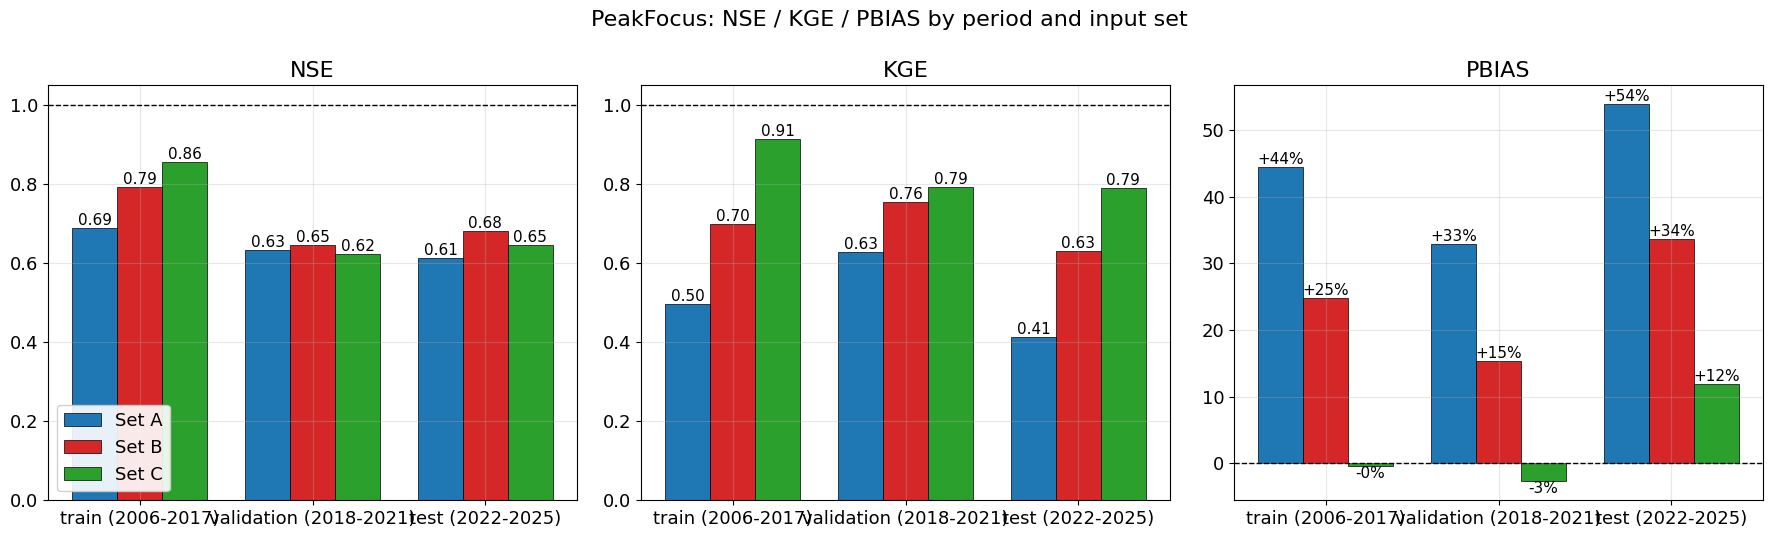

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, metric in zip(axes, ["NSE", "KGE", "PBIAS"]):
    x = np.arange(len(PERIODS))
    w = 0.26
    for i, s in enumerate(SETS):
        vals = [summaries[s]["metrics"][p][metric] for p in PERIODS]
        bars = ax.bar(x + (i - 1) * w, vals, w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f"{v:.2f}" if metric != "PBIAS" else f"{v:+.0f}%",
                    ha="center", va="bottom" if v >= 0 else "top", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels([PERIOD_LABEL[p] for p in PERIODS])
    ax.set_title(metric)
    ax.axhline(common.METRIC_IDEAL[metric], color="black", ls="--", lw=1)
    if metric in ("NSE", "KGE"):
        ax.set_ylim(max(-0.5, min(0, ax.get_ylim()[0])), 1.05)
axes[0].legend(loc="lower left")
fig.suptitle(f"{NAME}: NSE / KGE / PBIAS by period and input set", fontsize=16)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_metrics_by_period")
plt.show()

### 4.2 관측 vs 예측 산점도 (로그축)

행 = 기간, 열 = 입력세트. 로그축이므로 저유량(수 m³/s)과 홍수(수천 m³/s)의 거동을 한 그림에서 볼 수 있습니다.
1:1 선 아래로 휘면 고유량 과소, 왼쪽 위로 퍼지면 저유량 과대입니다. 관측값 0 (전체의 약 16%) 은 0.1 로 잘라 표시합니다.

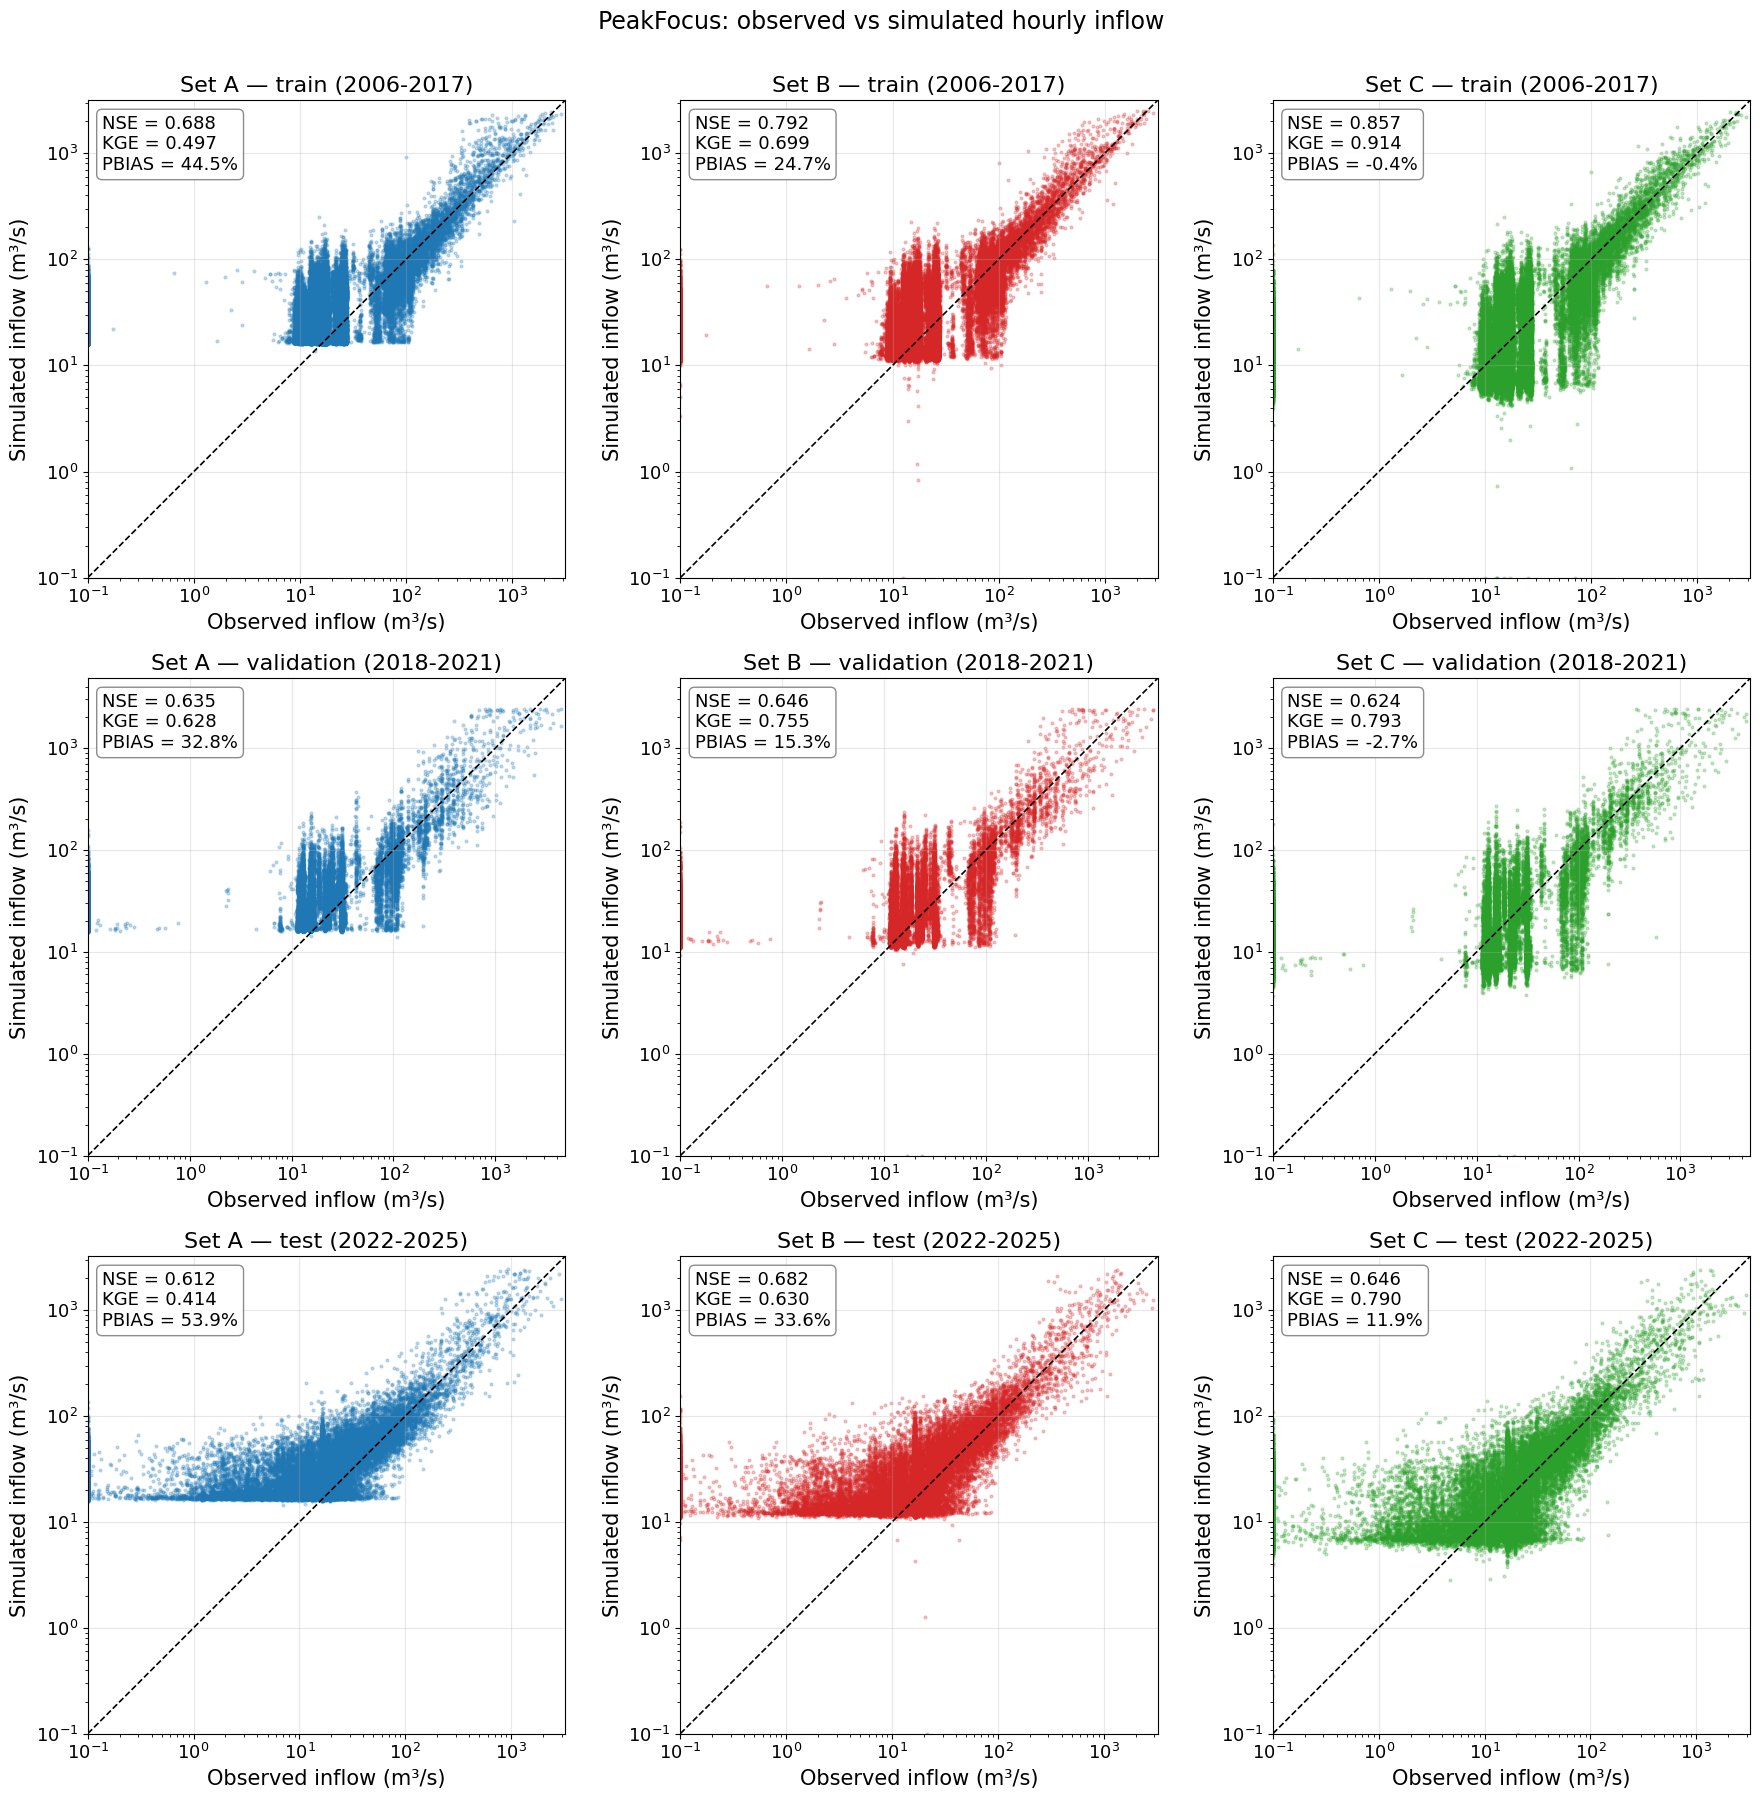

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
for i, p in enumerate(PERIODS):
    for j, s in enumerate(SETS):
        df = preds[s][preds[s]["period"] == p]
        common.plot_scatter(df["obs"], df["sim"], title=f"Set {s} — {PERIOD_LABEL[p]}", ax=axes[i, j], color=SET_COLOR[s])
fig.suptitle(f"{NAME}: observed vs simulated hourly inflow", fontsize=17, y=1.0)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_scatter")
plt.show()

## 5. 수문곡선 · 유량지속곡선

### 5.1 테스트 기간(2022–2025) 연도별 수문곡선

각 패널은 한 해의 시간 유입량입니다. 검은 선 = 관측, 색 선 = 입력세트별 예측, 위쪽 막대 = 유역평균 강우(역축).
홍수기(6–9월)의 첨두 크기와 상승·하강 시점, 건기의 저유량 수준을 봅니다.

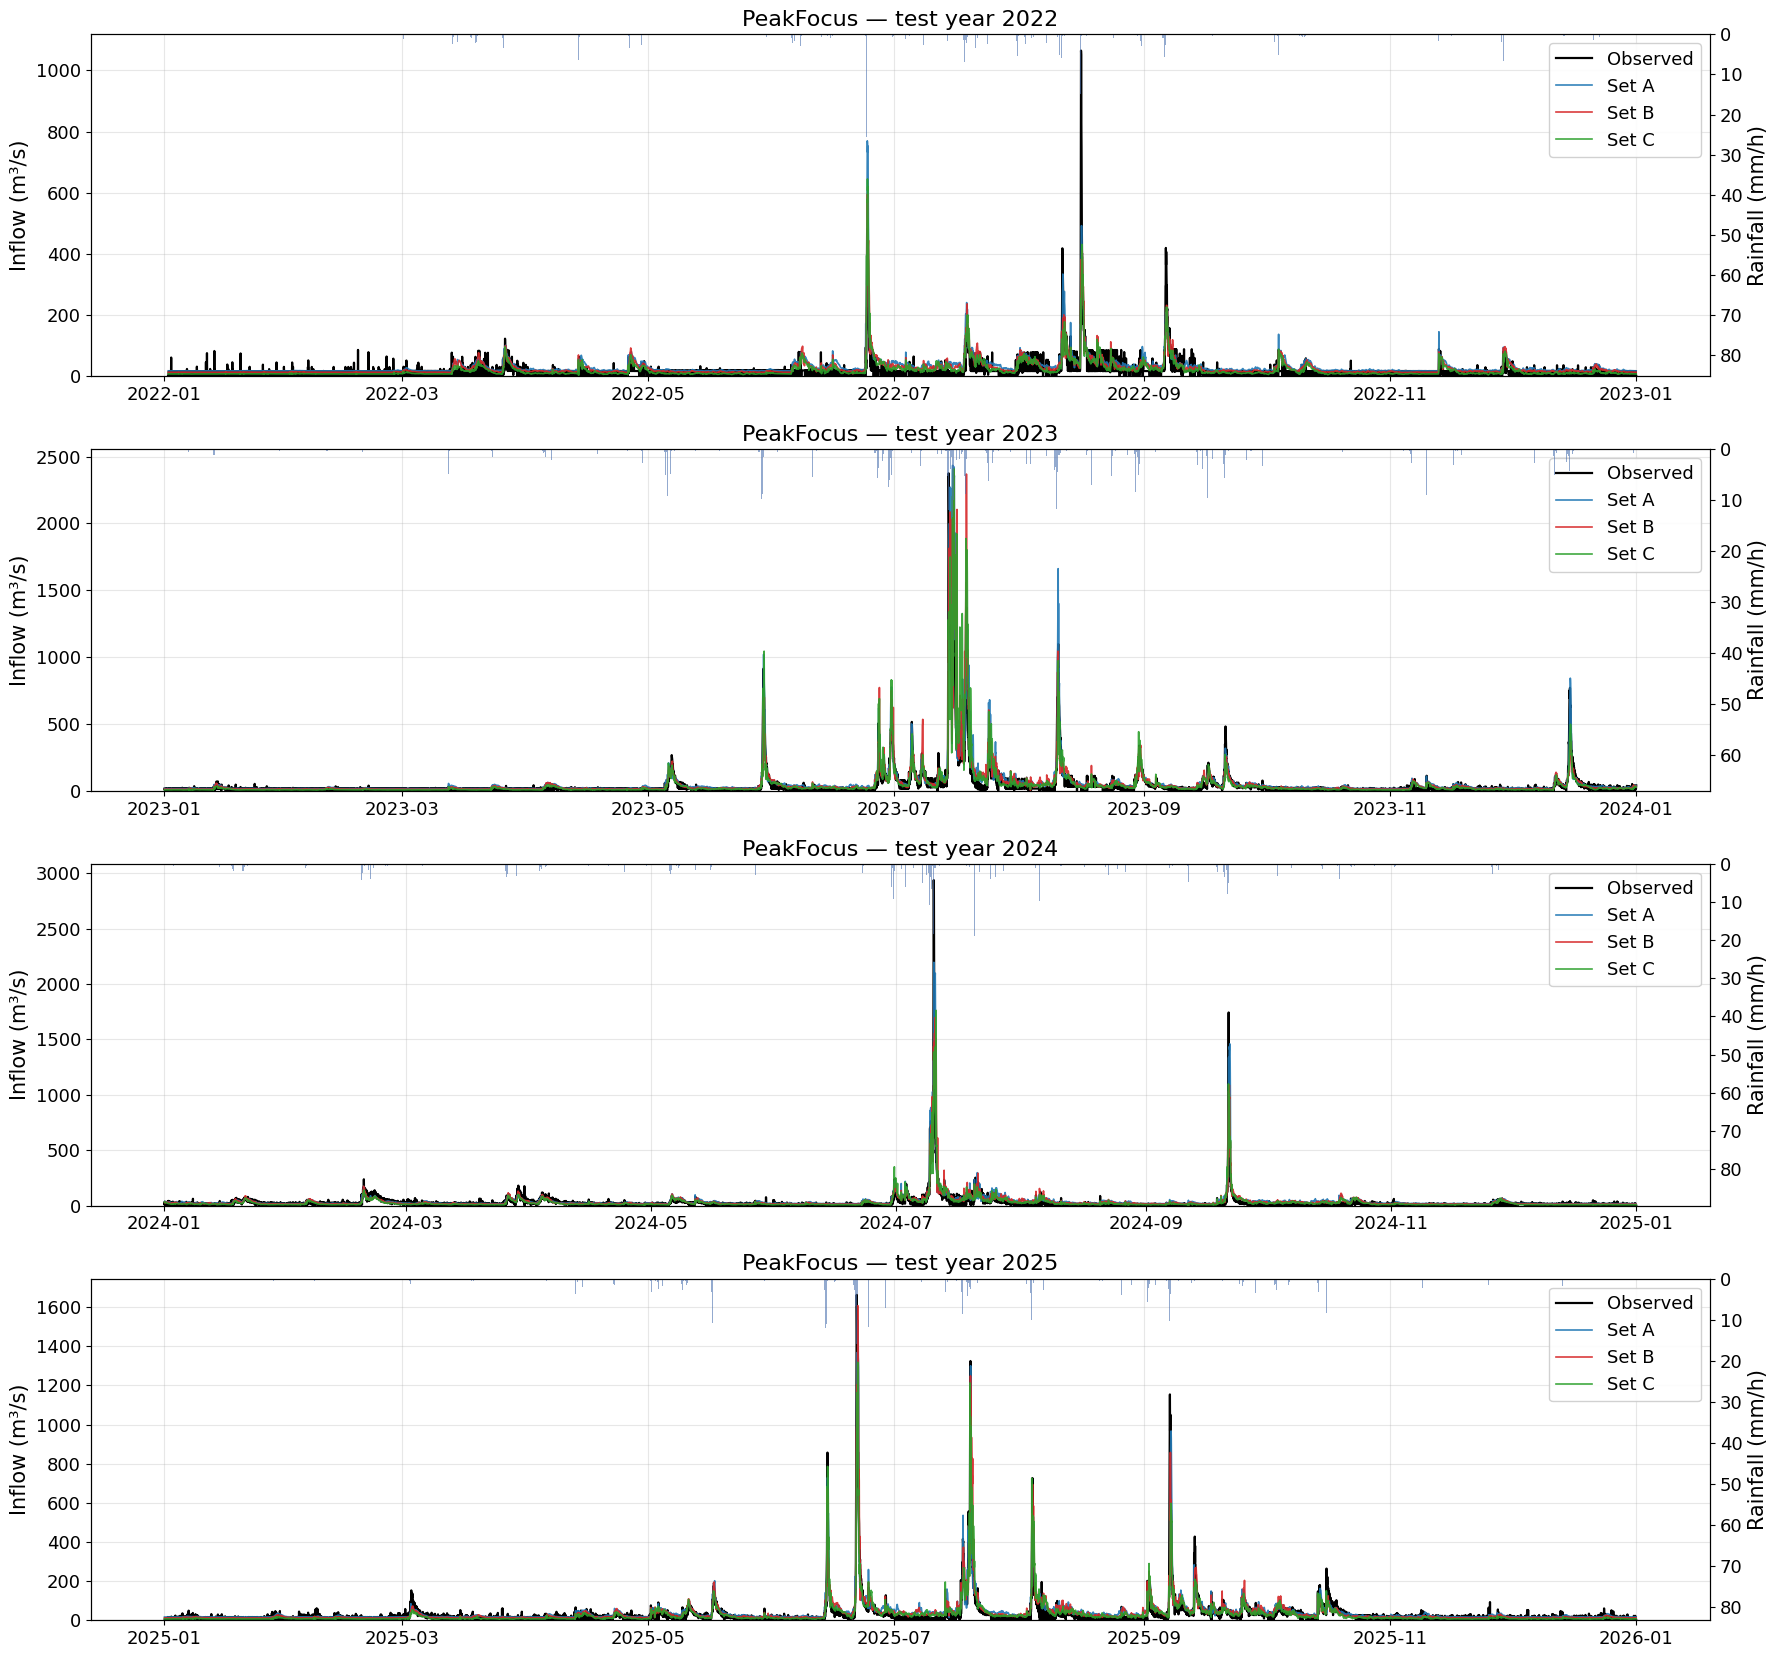

In [9]:
test_years = range(2022, 2026)
fig, axes = plt.subplots(len(test_years), 1, figsize=(18, 4.2 * len(test_years)))
for ax, year in zip(axes, test_years):
    start, end = f"{year}-01-01", f"{year}-12-31 23:00"
    obs = preds["A"].loc[start:end, "obs"]
    common.plot_hydrograph(obs, {f"Set {s}": preds[s].loc[start:end, "sim"] for s in SETS}, rain=rain.loc[start:end],
                           title=f"{NAME} — test year {year}", ax=ax, colors={f"Set {s}": SET_COLOR[s] for s in SETS},
                           styles={f"Set {s}": "-" for s in SETS}, sim_lw=1.2, obs_lw=1.6)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_hydrograph_test")
plt.show()

### 5.2 테스트 기간 최대 홍수사건 3개 확대

관측 첨두가 가장 큰 세 사건을 전후 5일 범위로 확대합니다. 시간 해상도이므로 첨두 **시각**까지 비교할 수 있습니다.

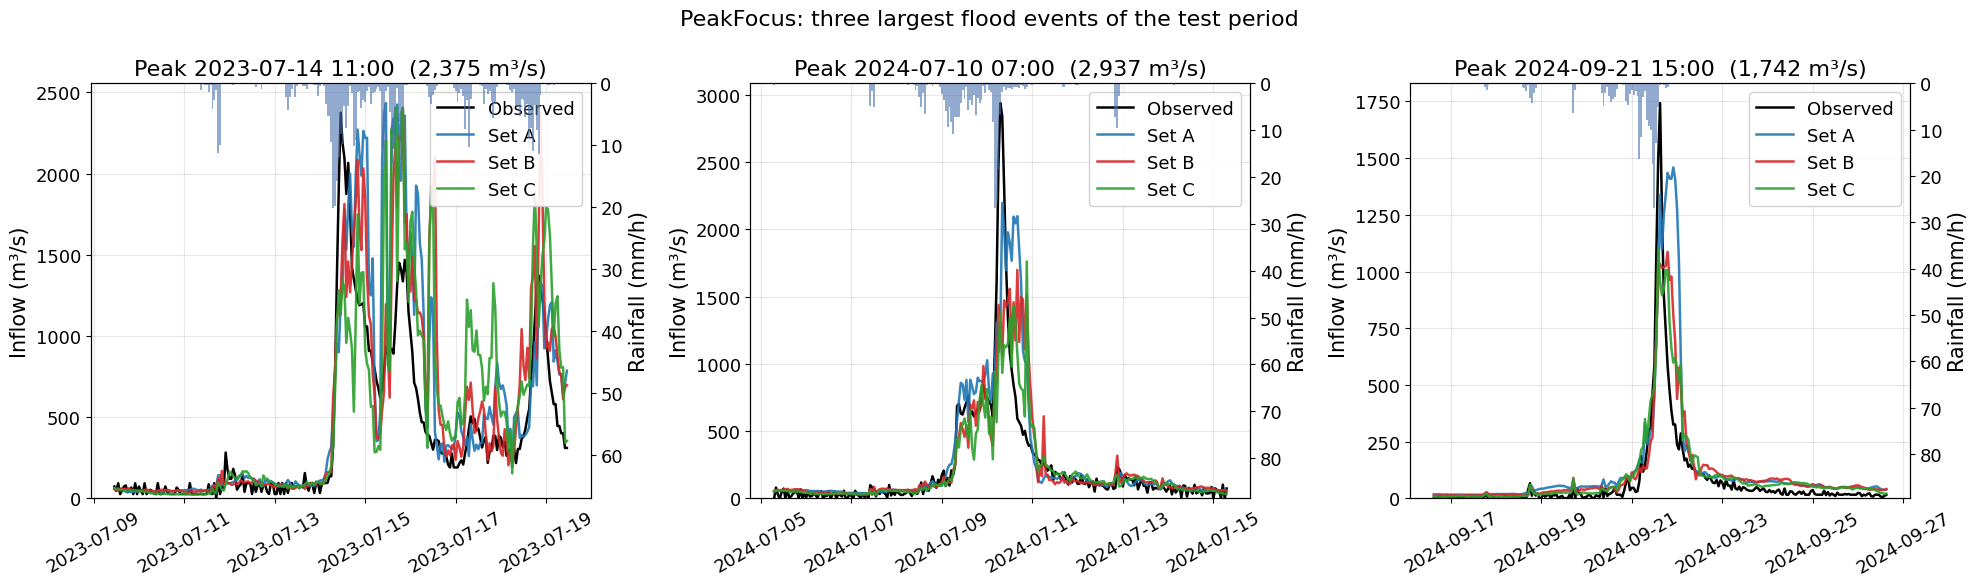

In [10]:
test_obs = preds["A"].loc[preds["A"]["period"] == "test", "obs"]
events = common.detect_events(test_obs, n_events=15)
top3 = sorted(events, key=lambda t: test_obs[t], reverse=True)[:3]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, peak in zip(axes, sorted(top3)):
    start, end = peak - pd.Timedelta(days=5), peak + pd.Timedelta(days=5)
    common.plot_hydrograph(preds["A"]["obs"], {f"Set {s}": preds[s]["sim"] for s in SETS}, rain=rain, start=start, end=end,
                           title=f"Peak {peak:%Y-%m-%d %H:00}  ({test_obs[peak]:,.0f} m³/s)", ax=ax,
                           colors={f"Set {s}": SET_COLOR[s] for s in SETS}, styles={f"Set {s}": "-" for s in SETS}, sim_lw=1.8)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"{NAME}: three largest flood events of the test period", fontsize=16)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_events_top3")
plt.show()

### 5.3 유량지속곡선 (테스트 기간)

고유량(FHV, 왼쪽 음영)과 저유량(FLV, 오른쪽 음영) 구간에서 관측 곡선과의 간격이 각각 FHV, FLV 지표에 해당합니다.

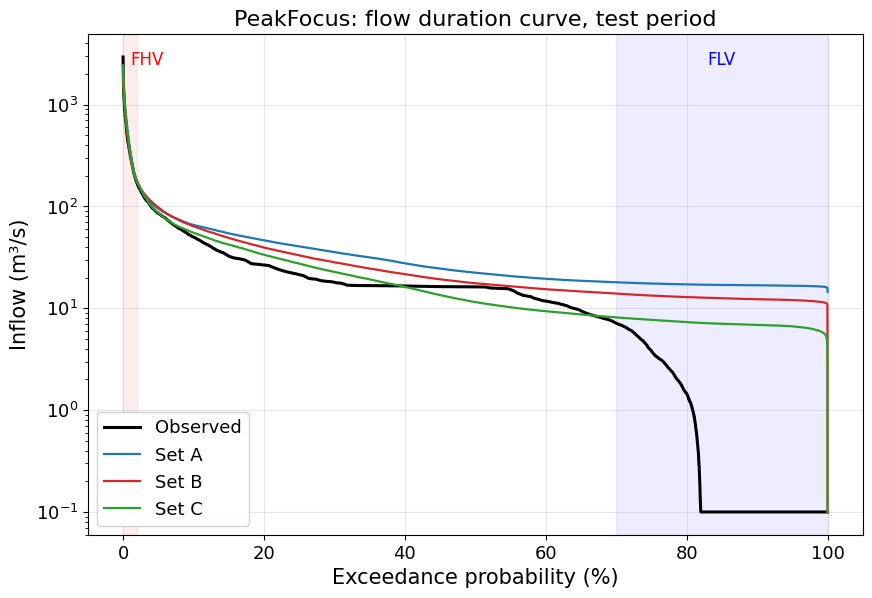

In [11]:
fig, ax = plt.subplots(figsize=(10, 6.5))
common.plot_fdc(test_obs, {f"Set {s}": preds[s].loc[preds[s]["period"] == "test", "sim"] for s in SETS},
                title=f"{NAME}: flow duration curve, test period", colors={f"Set {s}": SET_COLOR[s] for s in SETS}, ax=ax)
common.save_fig(fig, f"{MODEL}_fdc_test")
plt.show()

### 5.4 연도별 NSE

20년 전체를 연도별로 나눠 본 NSE 입니다. 배경 음영은 학습/검증/테스트 기간. 특정 해의 성능 급락은 보통 그 해의 큰 홍수를 놓쳤음을 뜻합니다.

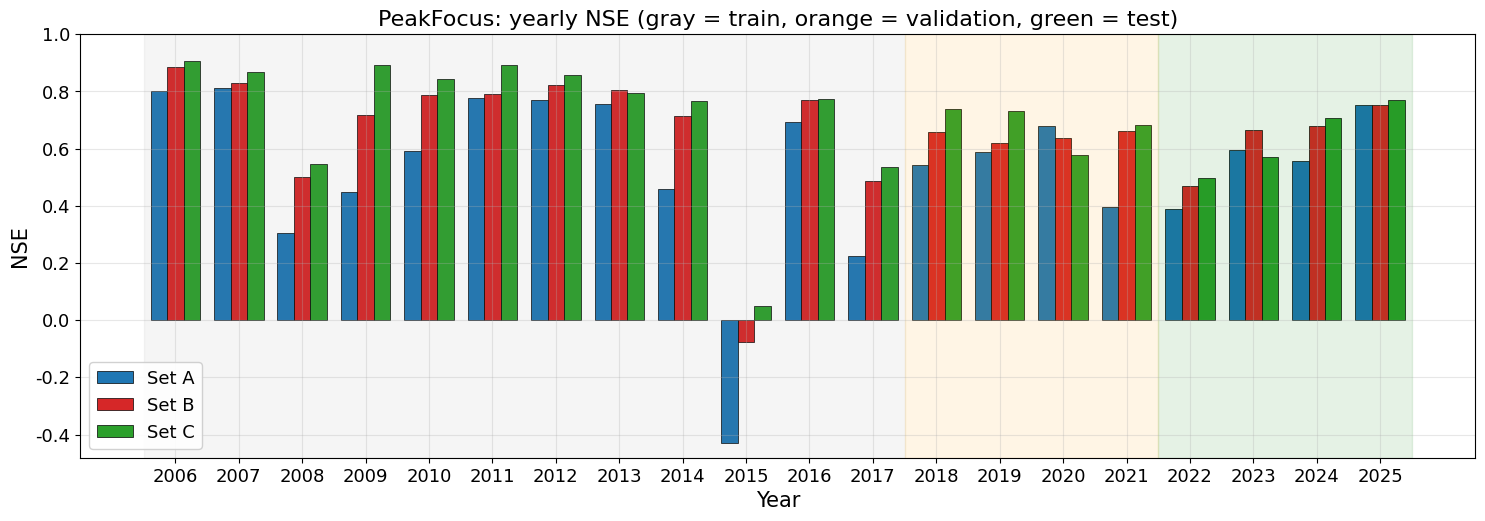

A             B             C       
        NSE    KGE    NSE    KGE    NSE    KGE
year                                          
2006  0.800  0.499  0.885  0.709  0.905  0.923
2007  0.811  0.589  0.831  0.711  0.869  0.883
2008  0.306  0.305  0.501  0.593  0.545  0.777
2009  0.450  0.117  0.719  0.398  0.893  0.795
2010  0.592  0.546  0.788  0.732  0.843  0.921
2011  0.777  0.628  0.791  0.695  0.893  0.899
2012  0.770  0.656  0.824  0.811  0.859  0.892
2013  0.756  0.715  0.806  0.874  0.795  0.795
2014  0.458  0.373  0.714  0.705  0.767  0.865
2015 -0.431  0.216 -0.077  0.431  0.051  0.545
2016  0.693  0.431  0.768  0.659  0.775  0.864
2017  0.225  0.261  0.485  0.564  0.535  0.764
2018  0.543  0.480  0.657  0.677  0.739  0.858
2019  0.588  0.511  0.621  0.582  0.730  0.787
2020  0.677  0.770  0.638  0.790  0.579  0.764
2021  0.397  0.385  0.662  0.723  0.681  0.826
2022  0.387  0.244  0.468  0.474  0.498  0.683
2023  0.594  0.418  0.667  0.626  0.569  0.684
2024  0.558  0.346  0.680  0.581  0.708  0.733
2025  0.752  0.542  0.752  0.682  0.769  0.809

In [12]:
yearly = {s: common.yearly_metrics(preds[s]) for s in SETS}
fig, ax = plt.subplots(figsize=(18, 5.5))
years = yearly["A"].index
w = 0.26
for i, s in enumerate(SETS):
    ax.bar(years + (i - 1) * w, yearly[s]["NSE"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
ax.axvspan(2005.5, 2017.5, color="gray", alpha=0.08)
ax.axvspan(2017.5, 2021.5, color="orange", alpha=0.10)
ax.axvspan(2021.5, 2025.5, color="green", alpha=0.10)
ax.set_ylim(max(-1, min(0, np.nanmin([yearly[s]["NSE"].min() for s in SETS]) - 0.05)), 1.0)
ax.set_xticks(years)
ax.set_ylabel("NSE")
ax.set_xlabel("Year")
ax.set_title(f"{NAME}: yearly NSE (gray = train, orange = validation, green = test)")
ax.legend(loc="lower left")
common.save_fig(fig, f"{MODEL}_yearly_nse")
plt.show()
display(pd.concat({s: yearly[s][["NSE", "KGE"]] for s in SETS}, axis=1).round(3))

## 6. 홍수 첨두 재현 (테스트 기간 상위 15개 사건)

관측 첨두를 서로 72시간 이상 떨어지도록 골라 독립 사건 15개를 정의하고, 사건마다

- **첨두 크기 오차** = (예측 첨두 − 관측 첨두) / 관측 첨두 × 100 (%) — 예측 첨두는 관측 첨두 ±24 h 안의 최대값
- **첨두 시각 오차** = 예측 첨두 시각 − 관측 첨두 시각 (h, + 는 지연)
- **사건 체적 오차** = 첨두 전 48 h ~ 후 96 h 구간 총량의 상대오차 (%)
- **사건 NSE** = 같은 구간의 NSE

를 계산합니다. 댐 운영에서는 평균적 적합도(NSE)보다 이 값들이 직접적인 관심사입니다.

In [13]:
event_tables = {s: common.load_saved_events(MODEL, s) for s in SETS}
best_set = max(SETS, key=lambda s: summaries[s]["metrics"]["test"]["NSE"])
print(f"테스트 NSE 가 가장 높은 입력세트: {best_set}")
t = event_tables[best_set].copy()
t[t.select_dtypes("number").columns] = t.select_dtypes("number").round(1)
display(t)
display(pd.DataFrame({s: summaries[s]["events_test"] for s in SETS}).round(2))

테스트 NSE 가 가장 높은 입력세트: B


,obs_peak,sim_peak,sim_peak_time,peak_error_pct,timing_error_h,volume_error_pct,event_NSE
obs_peak_time,,,,,,,
2022-08-16 07:00:00,1064.7,410.1,2022-08-16 14:00:00,-61.5,7.0,-11.0,0.5
2023-05-29 14:00:00,915.1,699.6,2023-05-29 18:00:00,-23.6,4.0,-13.1,0.7
2023-06-27 02:00:00,506.0,772.1,2023-06-27 07:00:00,52.6,5.0,23.2,0.5
2023-07-05 08:00:00,515.2,287.2,2023-07-05 16:00:00,-44.3,8.0,5.0,0.3
2023-07-14 11:00:00,2375.1,2085.4,2023-07-14 20:00:00,-12.2,9.0,29.7,0.4
2023-07-18 20:00:00,1372.7,2369.0,2023-07-18 21:00:00,72.6,1.0,54.3,0.4
2023-08-10 16:00:00,1097.7,1044.1,2023-08-10 14:00:00,-4.9,-2.0,0.3,0.8
2023-12-15 13:00:00,769.9,363.7,2023-12-15 16:00:00,-52.8,3.0,-29.5,0.5
2024-07-10 07:00:00,2936.9,1697.7,2024-07-10 16:00:00,-42.2,9.0,1.2,0.6


,A,B,C
n_events,15.00,15.00,15.00
peak_error_mean_pct,-4.82,-14.31,-13.72
peak_error_median_pct,-2.87,-21.70,-11.39
peak_abs_error_mean_pct,17.77,31.00,25.43
timing_error_mean_h,3.87,3.87,3.80
timing_abs_error_mean_h,4.13,4.27,5.27
timing_within_3h_frac,0.67,0.47,0.53
peak_within_20pct_frac,0.67,0.33,0.47
volume_error_mean_pct,21.21,12.43,11.30
event_NSE_median,0.58,0.56,0.64


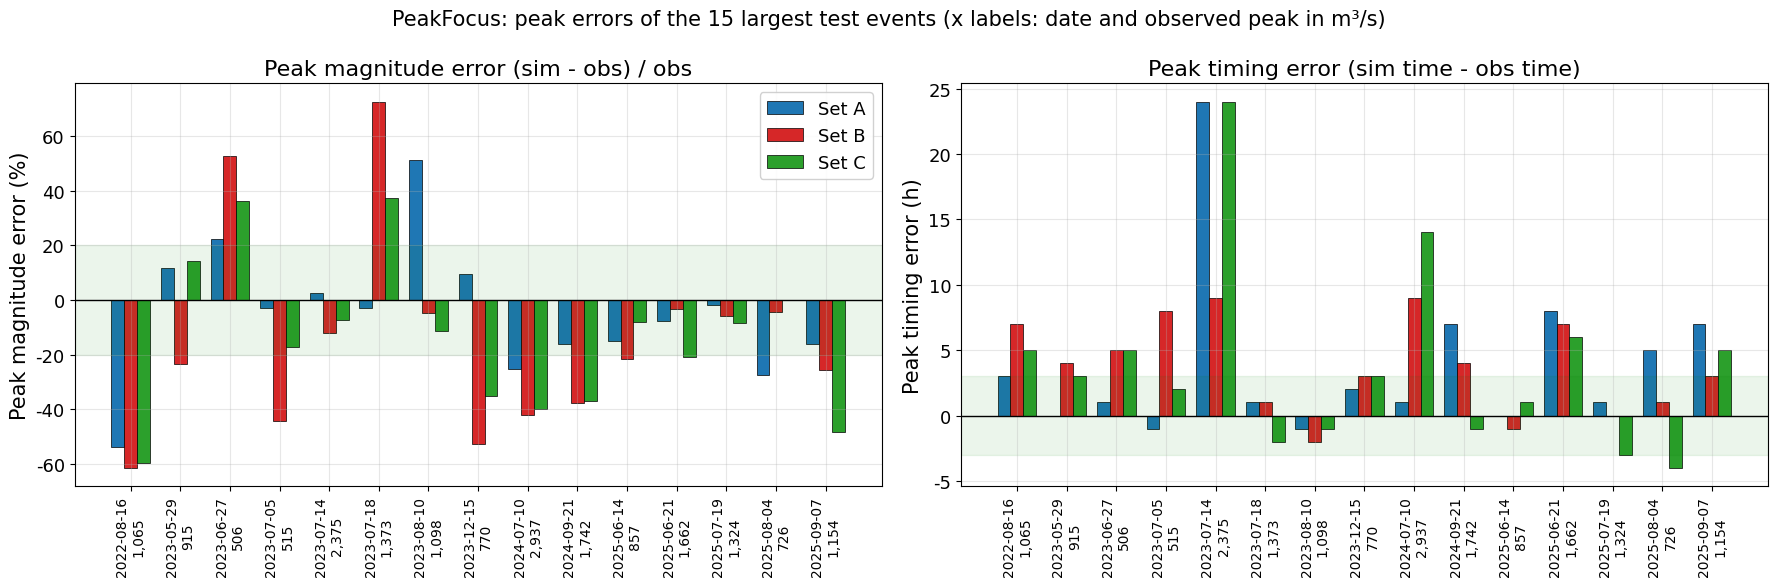

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
table = event_tables["A"]
x = np.arange(len(table))
w = 0.26
for i, s in enumerate(SETS):
    t = event_tables[s].reindex(table.index)
    axes[0].bar(x + (i - 1) * w, t["peak_error_pct"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
    axes[1].bar(x + (i - 1) * w, t["timing_error_h"], w, label=f"Set {s}", color=SET_COLOR[s], edgecolor="black", lw=0.5)
labels = [f"{t:%Y-%m-%d}\n{v:,.0f}" for t, v in zip(table.index, table["obs_peak"])]
for ax, ylabel, title in zip(axes, ["Peak magnitude error (%)", "Peak timing error (h)"],
                             ["Peak magnitude error (sim - obs) / obs", "Peak timing error (sim time - obs time)"]):
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=90, fontsize=10)
    ax.axhline(0, color="black", lw=1)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].axhspan(-20, 20, color="green", alpha=0.08)
axes[1].axhspan(-3, 3, color="green", alpha=0.08)
axes[0].legend(loc="best")
fig.suptitle(f"{NAME}: peak errors of the 15 largest test events (x labels: date and observed peak in m³/s)", fontsize=15)
fig.tight_layout()
common.save_fig(fig, f"{MODEL}_peak_errors")
plt.show()

## 7. 결과 해석

### 7.1 자동 요약 (지표 기반)

아래 글은 `common.narrative_for_run()` 이 지표 값으로부터 규칙적으로 생성한 요약입니다. 모든 모델 노트북에 같은 규칙을 적용하므로
모델 간 서술이 일관됩니다.

In [15]:
for s in SETS:
    display(Markdown(common.narrative_for_run(summaries[s])))

**PeakFocus / 입력세트 A (basin-average rainfall)**
- 테스트 기간 NSE 0.612, KGE 0.414, RMSE 54.0 m³/s, PBIAS +53.9%.
- 학습 NSE 0.688, 검증 NSE 0.635: 테스트 기간에서 성능이 다소 낮아지지만 큰 과적합 징후는 없습니다.
- 전체 유량을 과대 추정하는 경향(PBIAS +53.9%)이 뚜렷합니다.
- 고유량 구간(FHV +18.3%)은 과대 재현되고, 저유량 구간(FLV +97.3%)은 크게 과대 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -2.9%, 평균 절대 첨두오차 17.8%, 첨두 시각 오차 평균 +3.9 h (±3 h 이내 67%, 크기 ±20% 이내 67%).
- 학습: 37 epoch (early stopping), 최적 epoch 21, epoch당 평균 20 s, 총 학습시간 12.2 min, 파라미터 92,762개.

**PeakFocus / 입력세트 B (station rainfall (7 gauges))**
- 테스트 기간 NSE 0.682, KGE 0.630, RMSE 48.9 m³/s, PBIAS +33.6%.
- 학습 NSE(0.792)와 테스트 NSE의 차이가 0.11로 커서 **과적합 또는 기간 간 수문특성 차이**가 의심됩니다.
- 전체 유량을 과대 추정하는 경향(PBIAS +33.6%)이 뚜렷합니다.
- 고유량 구간(FHV +6.5%)은 과대 재현되고, 저유량 구간(FLV -172.5%)은 과소 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -21.7%, 평균 절대 첨두오차 31.0%, 첨두 시각 오차 평균 +3.9 h (±3 h 이내 47%, 크기 ±20% 이내 33%).
- 학습: 37 epoch (early stopping), 최적 epoch 17, epoch당 평균 22 s, 총 학습시간 13.5 min, 파라미터 95,066개.

**PeakFocus / 입력세트 C (basin-average + station rainfall)**
- 테스트 기간 NSE 0.646, KGE 0.790, RMSE 51.5 m³/s, PBIAS +11.9%.
- 학습 NSE(0.857)와 테스트 NSE의 차이가 0.21로 커서 **과적합 또는 기간 간 수문특성 차이**가 의심됩니다.
- 전체 유량을 과대 추정하는 경향(PBIAS +11.9%)이 뚜렷합니다.
- 고유량 구간(FHV +5.9%)은 과대 재현되고, 저유량 구간(FLV -162.8%)은 과소 재현됩니다.
- 테스트 기간 상위 15개 홍수사건: 첨두 크기 오차 중앙값 -11.4%, 평균 절대 첨두오차 25.4%, 첨두 시각 오차 평균 +3.8 h (±3 h 이내 53%, 크기 ±20% 이내 47%).
- 학습: 44 epoch (early stopping), 최적 epoch 17, epoch당 평균 20 s, 총 학습시간 15.0 min, 파라미터 95,450개.

### 7.2 PeakFocus 의 결과 해석

**요약**: 테스트 NSE 0.61 (A), 0.68 (B), 0.65 (C), KGE 0.41–0.79. 첨두 전용 손실을 쓰는 모델이지만 전체 지표와 첨두 지표 모두 순환 모델에
미치지 못했다. 가장 두드러진 문제는 **총량 과대 추정**(PBIAS +12 ~ +54%)이다.

- **구현 수정**: 이식된 PeakFocus 는 입력창을 창별 평균·표준편차로 정규화하지만, 원 논문과 달리 목표(유입량) 이력이 입력에 없어 출력을
  역정규화할 수 없었다. 그 결과 강우의 절대 크기 정보가 사라져 학습 자료조차 맞추지 못했다(학습 NSE 0.3 수준, 테스트 NSE 0.15–0.21).
  본 연구에서는 `peakfocus_instance_norm: false` 옵션을 추가해 정규화를 끄고 전역 표준화 입력을 그대로 쓰도록 했고, 여기 보고된 값은 그
  결과이다(정규화를 켠 run 은 `runs/_instnorm_peakfocus/` 에 보관).
- **총량·저유량**: 세트 A 는 PBIAS +54% 로 저유량을 크게 과대 추정한다(KGE 0.41). 첨두 가중 MSE 와 focal loss 가 첨두 시각에 손실을
  집중시키면서 **비첨두 구간(전체의 95% 이상)의 정확도가 희생**된 것으로 해석된다. 관측소별 강우를 추가한 B, C 에서 편향이 줄어든다
  (C: +12%, KGE 0.79).
- **홍수 첨두**: 세트 A 는 첨두 크기 오차 중앙값 −2.9%, 평균 절대 오차 18%, ±20% 이내 67% 로 **첨두 크기만 보면 LSTM-A(17%, 53%)와
  대등**하다. 그러나 첨두 시각 오차가 4.1–5.3 h 로 순환 모델(1–2 h)의 3–4배이고, 사건 NSE 중앙값 0.56–0.64 로 사건 수문곡선의 모양은
  거칠다. 2023-07-18 (+73%), 2023-06-27 (+53%) 처럼 첨두를 크게 과대 추정한 사건도 있다.
- **구조적 해석**: 인코더가 시각별 MLP 와 720 → 24 의 선형 시간 투영으로 구성되어 저류 상태가 없고, 시간 정보는 위치 임베딩과 선형 투영이
  담당한다. 첨두 "위치" 분류(MSM-PL)가 디코더를 게이팅하지만, 분류 자체가 입력 강우만으로 이루어지므로 유출 지체를 정확히 잡지 못해 시각
  오차가 커진 것으로 보인다. 첨두 라벨 임계(표준화 1.0)·창(±3 h)·손실 가중치는 기본값이며 튜닝 여지가 크다.
- **과적합**: 학습 NSE 0.69–0.86 대 테스트 0.61–0.68, 검증 loss 최소 17–21 epoch 후 악화. 파라미터 93–95k.
- **비용**: 20–22 s/epoch (LSTM 의 2.5배).


## 8. 요약

아래 표가 이 노트북의 최종 결과이며, `results/peakfocus_<set>/summary.json` 으로 저장되어 비교 노트북에서 사용됩니다.

In [16]:
summary_table = pd.DataFrame({
    f"Set {s}": {
        "parameters": summaries[s]["n_parameters"],
        "epochs trained": summaries[s]["epochs_trained"],
        "best epoch": summaries[s]["best_epoch"],
        "early stopped": summaries[s]["early_stopped"],
        "s / epoch": round(summaries[s]["epoch_time_mean_s"], 1),
        "training time (min)": round(summaries[s]["train_time_total_s"] / 60, 1),
        "test NSE": round(summaries[s]["metrics"]["test"]["NSE"], 3),
        "test KGE": round(summaries[s]["metrics"]["test"]["KGE"], 3),
        "test RMSE (m³/s)": round(summaries[s]["metrics"]["test"]["RMSE"], 1),
        "test PBIAS (%)": round(summaries[s]["metrics"]["test"]["PBIAS"], 1),
        "test FHV (%)": round(summaries[s]["metrics"]["test"]["FHV"], 1),
        "peak |error| mean (%)": round(summaries[s]["events_test"]["peak_abs_error_mean_pct"], 1),
        "peak |timing| mean (h)": round(summaries[s]["events_test"]["timing_abs_error_mean_h"], 1),
    } for s in SETS})
display(summary_table)
summary_table.to_csv(common.RESULTS_DIR / f"{MODEL}_summary_table.csv")

,Set A,Set B,Set C
parameters,92762,95066,95450
epochs trained,37,37,44
best epoch,21,17,17
early stopped,True,True,True
s / epoch,19.6,21.8,20.3
training time (min),12.2,13.5,15.0
test NSE,0.612,0.682,0.646
test KGE,0.414,0.63,0.79
test RMSE (m³/s),54.0,48.9,51.5
test PBIAS (%),53.9,33.6,11.9
